# 02 — Experiment results and error analysis

Use the **Europarl multidoc v2** outputs. This notebook reads saved results; it does not train, generate translations, or call an LLM. Run from `notebooks/` or the project root. Begin with validation; switch to test only after the experimental decisions are fixed. Missing arms are displayed as pending. Results from the earlier pilot are never loaded here.

A = Sentence LoRA; B = Context LoRA (`src </s> previous_src`); C = A post-edited by the LLM; D = B post-edited by the LLM. All use the same pair-balanced training for A/B.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATASET = "europarl_multidoc_v2"
SPLIT = "validation"  # Set to "test" only after choosing the configuration on validation.
assert SPLIT in {"validation", "test"}
DATA_DIR = PROJECT_ROOT / "data" / "processed" / DATASET
assert DATA_DIR.is_dir(), f"Missing dataset: {DATA_DIR}"
ARMS = {
    "A": "sentence_lora_balanced_multidoc_v2",
    "B": "context_lora_balanced_multidoc_v2",
    "C": "sentence_lora_balanced_multidoc_v2_llm",
    "D": "context_lora_balanced_multidoc_v2_llm",
}
KEYS = ["pair", "doc_id", "src_sent_id", "tgt_sent_id"]
print(f"Project: {PROJECT_ROOT} | Dataset: {DATASET} | Split: {SPLIT}")


Project: D:\CIS600\context-mt | Dataset: europarl_multidoc_v2 | Split: validation


## Dataset provenance

Check the split and manifest before loading model outputs. A/B/C/D must refer to these exact examples. The held-out test split is not loaded during the default validation analysis.


In [2]:
manifest = json.loads((DATA_DIR / "summary.json").read_text(encoding="utf-8"))
data_path = DATA_DIR / f"{SPLIT}.csv"
import hashlib
actual_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert manifest["csv_sha256"][SPLIT] == actual_hash, "Dataset differs from summary.json"
truth = pd.read_csv(data_path)
assert truth["split"].eq(SPLIT).all()
assert not truth.duplicated(KEYS).any(), "Duplicate example keys in dataset"
display(truth.groupby("pair").agg(examples=("src", "size"), documents=("doc_id", "nunique")))
print(f"SHA256 {SPLIT}: {actual_hash}")


,examples,documents
pair,,
en-de,100,10
en-fr,50,10


SHA256 validation: 7fe4dfc70f881e046999659049e88e67601709e4d50cfa662494d6bcde8df8ee


## Four-arm comparison

A/B prediction tables come from mBART evaluation; C/D come from LLM post-editing. Scores use the saved SacreBLEU and chrF metrics with one consistent reference per example. The code verifies both dataset hash provenance and row alignment before displaying a model.


In [3]:
reports, predictions, missing = {}, {}, []
for arm, run in ARMS.items():
    pred_path = PROJECT_ROOT / "outputs" / "predictions" / f"{run}_{SPLIT}.csv"
    metric_path = PROJECT_ROOT / "outputs" / "metrics" / f"{run}_{SPLIT}_metrics.json"
    if not pred_path.is_file() or not metric_path.is_file():
        missing.append(f"{arm}: {pred_path.name} / {metric_path.name}")
        continue
    report = json.loads(metric_path.read_text(encoding="utf-8"))
    if arm in "AB":
        assert report.get("dataset_sha256") == actual_hash, f"{arm}: metric dataset hash mismatch"
        assert report.get("split") == SPLIT, f"{arm}: wrong split"
    else:
        assert report.get("split") == SPLIT and not report.get("smoke_test"), f"{arm}: wrong split or smoke result"
    table = pd.read_csv(pred_path)
    assert len(table) == len(truth), f"{arm}: example count mismatch"
    assert not table.duplicated(KEYS).any(), f"{arm}: duplicate keys"
    aligned = truth[KEYS + ["src", "tgt", "previous_src"]].merge(
        table[KEYS + ["src", "tgt", "previous_src", "prediction"]],
        on=KEYS, how="left", validate="one_to_one", suffixes=("_gold", "_out"),
    )
    assert aligned["prediction"].notna().all(), f"{arm}: missing predictions"
    for field in ("src", "tgt", "previous_src"):
        assert aligned[f"{field}_gold"].equals(aligned[f"{field}_out"]), f"{arm}: {field} mismatch"
    reports[arm], predictions[arm] = report, aligned["prediction"].reset_index(drop=True)
print("Available arms:", ", ".join(reports) or "none yet")
if missing:
    print("Pending outputs:")
    for entry in missing:
        print(" -", entry)


Available arms: A, B, C, D


,arm,pair,N,BLEU,chrF
0,A,en-de,100,28.428,58.441
1,A,en-fr,50,33.723,60.071
2,A,macro,150,31.075,59.256
3,B,en-de,100,28.805,58.515
4,B,en-fr,50,34.518,60.516
5,B,macro,150,31.662,59.516
6,C,en-de,100,27.582,58.093
7,C,en-fr,50,35.574,60.335
8,C,macro,150,31.578,59.214
9,D,en-de,100,28.468,58.461


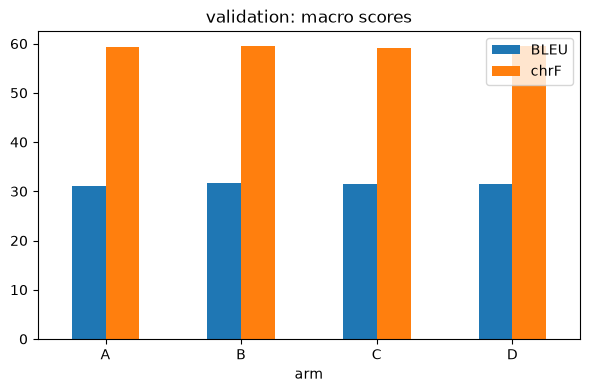

In [4]:
rows = []
for arm, report in reports.items():
    for pair in ("en-de", "en-fr"):
        pair_report = report["pairs"][pair]
        score = pair_report if arm in "AB" else pair_report["postedited"]
        rows.append({"arm": arm, "pair": pair, "N": pair_report["num_examples"],
                     "BLEU": score["sacrebleu"], "chrF": score["chrf"]})
    pair_rows = rows[-2:]
    rows.append({"arm": arm, "pair": "macro", "N": sum(r["N"] for r in pair_rows),
                 "BLEU": sum(r["BLEU"] for r in pair_rows) / 2,
                 "chrF": sum(r["chrF"] for r in pair_rows) / 2})
score_table = pd.DataFrame(rows, columns=["arm", "pair", "N", "BLEU", "chrF"])
if score_table.empty:
    print("Validation predictions and metrics are pending.")
else:
    display(score_table.round(3))
    macro = score_table[score_table["pair"] == "macro"].set_index("arm")
    display(macro[["BLEU", "chrF"]].plot.bar(rot=0, figsize=(7, 4), title=f"{SPLIT}: macro scores").figure)
    plt.close("all")


## Paired changes and qualitative examples

Compare translations for the **same** rows. Sentence-level chrF identifies candidates for manual inspection; it does not prove that a model resolved a pronoun or improved discourse. Review the source, preceding source and both translations before writing such claims in the report.


In [5]:
from sacrebleu.metrics import CHRF
chrf_metric = CHRF()
reference = truth["tgt"].tolist()
comparisons = {"context B − A": ("A", "B"), "LLM C − A": ("A", "C"),
               "LLM D − B": ("B", "D"), "context D − C": ("C", "D")}
summary = []
example_tables = {}
for name, (before, after) in comparisons.items():
    if before not in predictions or after not in predictions:
        continue
    old, new = predictions[before].tolist(), predictions[after].tolist()
    delta = [chrf_metric.sentence_score(b, [ref]).score -
             chrf_metric.sentence_score(a, [ref]).score
             for a, b, ref in zip(old, new, reference)]
    review = truth[KEYS + ["previous_src", "src", "tgt"]].copy()
    review[f"prediction_{before}"] = old
    review[f"prediction_{after}"] = new
    review["delta_sentence_chrF"] = delta
    example_tables[name] = review
    summary.append({"comparison": name, "changed": sum(a != b for a, b in zip(old, new)),
                    "helped": sum(d > 1e-9 for d in delta), "hurt": sum(d < -1e-9 for d in delta),
                    "tied": sum(abs(d) <= 1e-9 for d in delta),
                    "mean_sentence_chrF_delta": sum(delta) / len(delta)})
if summary:
    display(pd.DataFrame(summary).round(3))
    for name, table in example_tables.items():
        print(f"{name} — five largest positive changes")
        display(table.nlargest(5, "delta_sentence_chrF"))
        print(f"{name} — five largest negative changes")
        display(table.nsmallest(5, "delta_sentence_chrF"))
else:
    print("At least two complete arms are needed for paired examples.")


,comparison,changed,helped,hurt,tied,mean_sentence_chrF_delta
0,context B − A,78,46,31,73,0.559
1,LLM C − A,126,61,63,26,-0.381
2,LLM D − B,90,46,43,61,0.095
3,context D − C,110,58,51,41,1.035


context B − A — five largest positive changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_A,prediction_B,delta_sentence_chrF
85,en-de,en/ep-08-05-19-027.xml,366,412,"I do not believe, however, that this has been ...",Quite the reverse.,Ganz im Gegenteil.,Ganz umgekehrt.,Ganz im Gegenteil.,80.976014
147,en-fr,en/ep-08-01-14-018.xml,87,87,One reason for that is the stubborn attitude o...,I thank Stavros Dimas for ensuring that we now...,Je remercie M. Dimas pour avoir fait en sorte ...,Je remercie Stavros Dimas d'avoir assuré que n...,Je remercie Stavros Dimas d'avoir fait en sort...,17.559610
44,en-de,en/ep-10-05-18-017.xml,175,182,This oil disaster should make us all consider ...,We should also concentrate all our mental ener...,Wir sollten alle unsere mentalen Energien und ...,Wir sollten auch unsere geistigen Kräfte und u...,Wir sollten auch alle unsere mentalen Energien...,15.286796
50,en-fr,en/ep-08-05-19-027.xml,279,286,"(RO) First of all, I would like to congratulat...","Nevertheless, I would like to make an observat...",J'aimerais toutefois faire une observation rel...,Je voudrais néanmoins faire une remarque au su...,Je voudrais néanmoins faire une observation au...,13.021418
106,en-de,en/ep-05-10-12.xml,61,70,This is an opportunist action on behalf of the...,We should wait to hear what the discussions wi...,"Wir sollten abwarten, wie die Gespräche verlau...","Wir sollten warten, zu hören, was die Diskussi...","Wir sollten warten, um zu hören, was die Disku...",9.578903


context B − A — five largest negative changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_A,prediction_B,delta_sentence_chrF
130,en-de,en/ep-01-03-15.xml,1708,1807,"I feel I am in good company with Mr Staes, but...","Commissioner, as far as this matter is concern...","Diesbezüglich können Sie, Herr Kommissar, heut...","Herr Kommissar, in dieser Angelegenheit könnte...",Herr Kommissar!,-46.128765
56,en-fr,en/ep-08-01-14-018.xml,32,32,"This was proposed, while for developing countr...","After all, we are talking about substances tha...","Après tout, nous parlons de substances qui son...","Après tout, nous parlons de substances qui son...","Après tout, nous parlons de substances interdi...",-16.241216
13,en-de,en/ep-05-06-23.xml,54,55,Countries round the world are coming together ...,"Until the second half of the 20th century, ind...",Bis zur zweiten Hälfte des 20. & #160; Jahrhun...,Bis zur zweiten Hälfte des 20. Jahrhunderts ha...,Bis zur zweiten Hälfte des 20. Jahrhunderts be...,-13.011283
4,en-de,en/ep-10-05-18-017.xml,61,61,This recent disaster shows us that no one is i...,The Obama government was forced to retreat by ...,Die Regierung Obama wurde durch das Ausmaß der...,Die Obama-Regierung wurde durch die Ausmaße de...,"Die Obama-Regierung war gezwungen, sich aufgru...",-12.661708
34,en-de,en/ep-01-03-15.xml,560,594,The policy paper and action plan will be the C...,"Obviously, in preparing this policy document w...",Nun können wir bei der Ausarbeitung dieses str...,Natürlich können wir jetzt bei der Ausarbeitun...,Natürlich können wir jetzt bei der Ausarbeitun...,-10.837531


LLM C − A — five largest positive changes


... (7 outputs left out)

context D − C — five largest positive changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_C,prediction_D,delta_sentence_chrF
85,en-de,en/ep-08-05-19-027.xml,366,412,"I do not believe, however, that this has been ...",Quite the reverse.,Ganz im Gegenteil.,Ganz und gar nicht.,Ganz im Gegenteil.,83.628663
102,en-fr,en/ep-07-11-14-016.xml,68,70,"The market of thieves, the market of people wh...",What sort of rights are we talking about?,De quelle sorte de droits parlons -nous ?,De quelles droits s'agit-il ?,De quel genre de droits parlons-nous ?,38.340629
93,en-fr,en/ep-05-10-12.xml,286,293,The right to be received should be an inaliena...,A decent and humane reception should be provid...,Le camp d attente de Melilla doit assurer une ...,Un accueil décent et humain devrait être提供的翻译文...,Une réception digne et humaine devrait être as...,31.663584
108,en-de,en/ep-08-05-19-027.xml,328,372,I have a couple of remarks.,Mrs Kauppi mentioned financial services.,Frau Kauppi erwähnte den Bereich der Finanzdie...,Frau Kauppi erwähnte die Finanzdienste.,Frau Kauppi erwähnte die Finanzdienstleistungen.,19.588851
31,en-fr,en/ep-08-01-14-018.xml,46,46,The proposal before us is a good regulation an...,Things that are not understood will of course ...,Les choses qui ne sont pas comprises n'auront ...,Les choses qui ne sont pas comprises ne feront...,Les choses qui ne sont pas comprises ne feront...,15.666379


context D − C — five largest negative changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_C,prediction_D,delta_sentence_chrF
59,en-de,en/ep-08-01-14-018.xml,21,22,"Madam President, I should like to express my s...",The European Commission is able to accept the ...,Die Europäische Kommission kann das Kompromiss...,Die Europäische Kommission kann das Kompromiss...,"Frau Präsidentin, ich möchte meine Zufriedenhe...",-29.986860
100,en-de,en/ep-07-11-14-016.xml,64,67,"(ES) Mr President, Commissioner Borg's reply t...",But what is it we are talking about?,Worüber reden wir da aber eigentlich?,Aber worüber reden wir?,Aber worüber sprechen wir?,-17.966398
13,en-de,en/ep-05-06-23.xml,54,55,Countries round the world are coming together ...,"Until the second half of the 20th century, ind...",Bis zur zweiten Hälfte des 20. & #160; Jahrhun...,Bis zur zweiten Hälfte des 20. Jahrhunderts ha...,Bis zur zweiten Hälfte des 20. Jahrhunderts be...,-14.326567
101,en-fr,en/ep-08-01-14-018.xml,21,21,"Madam President, I should like to express my s...",The European Commission is able to accept the ...,La Commission européenne peut accepter le paqu...,La Commission européenne est en mesure d'accep...,"Madame la Présidente, la Commission européenne...",-14.209688
23,en-fr,en/ep-09-05-06-014.xml,113,115,The Council recalls the European Union's willi...,The Council welcomes the Commission's intentio...,Le Conseil se félicite de l'intention de la Co...,Le Conseil se félicite de l'intention de la Co...,Le Conseil se félicite de l'intention de la Co...,-12.630545


## Semantic score: COMET

Read the v2 COMET report after all four validation arms are scored. Compare mean COMET by pair and equal-pair macro score; this remains a descriptive comparison rather than a significance test.


In [6]:
comet_path = PROJECT_ROOT / "outputs" / "metrics" / f"comet_{SPLIT}_multidoc_v2_metrics.json"
if comet_path.is_file():
    comet_report = json.loads(comet_path.read_text(encoding="utf-8"))
    assert comet_report.get("dataset") == "multidoc_v2"
    assert comet_report.get("split") == SPLIT
    assert comet_report["inputs"]["dataset"]["sha256"] == actual_hash
    comet_rows = []
    for arm, details in comet_report["arms"].items():
        for pair, metrics in details["pairs"].items():
            comet_rows.append({"arm": arm, "pair": pair, "COMET": metrics["comet_mean"]})
        comet_rows.append({"arm": arm, "pair": "macro",
                           "COMET": details["macro_average_comet"]})
    display(pd.DataFrame(comet_rows).round(4))
    display(pd.DataFrame([{"comparison": name, "COMET delta": value["macro_comet_delta"]}
                          for name, value in comet_report["comparisons"].items()]).round(4))
else:
    print(f"COMET pending: {comet_path.name}")


,arm,pair,COMET
0,A,en-de,0.8667
1,A,en-fr,0.8623
2,A,macro,0.8645
3,B,en-de,0.8669
4,B,en-fr,0.8637
5,B,macro,0.8653
6,C,en-de,0.8697
7,C,en-fr,0.8532
8,C,macro,0.8615
9,D,en-de,0.8668


,comparison,COMET delta
0,context_without_llm,0.0008
1,llm_sentence,-0.0030
2,llm_context,0.0039
3,context_with_llm,0.0077


## Sampling ablation: Top-k and Top-p

Read the separate validation experiment after `sample_decoding_v2.py` and `evaluate_decoding_comet_v2.py` finish. Beam search remains the frozen B reference. Sampling candidates are selected by Qwen without seeing the gold translation. Inspect both language pairs; do not choose a test setting from test scores.


In [7]:
if SPLIT == 'validation':
    decoding_root = PROJECT_ROOT / 'outputs' / 'decoding' / 'multidoc_v2'
    folders = {
        'Top-k': decoding_root / 'validation_top_k_k50_n3_t0p8_seed42',
        'Top-p': decoding_root / 'validation_top_p_p0p9_n3_t0p8_seed42',
    }
    decoding_rows = []
    for name, folder in folders.items():
        path = folder / 'metrics.json'
        if not path.is_file():
            print(f'Pending {name}: {path}')
            continue
        result = json.loads(path.read_text(encoding='utf-8'))
        assert result['config']['dataset_sha256'] == actual_hash
        assert result['config']['split'] == 'validation' and not result['smoke_test']
        for pair, values in result['pairs'].items():
            decoding_rows.append({'method': name, 'pair': pair, 'N': values['num_examples'],
                                  'changed': values['changed'],
                                  'beam BLEU': values['beam_bleu'],
                                  'selected BLEU': values['reranked_bleu'],
                                  'beam chrF': values['beam_chrf'],
                                  'selected chrF': values['reranked_chrf']})
    if decoding_rows:
        display(pd.DataFrame(decoding_rows).round(3))
    comet_sampling_path = decoding_root / 'validation_comet_comparison' / 'metrics.json'
    if comet_sampling_path.is_file():
        sampling_comet = json.loads(comet_sampling_path.read_text(encoding='utf-8'))
        assert sampling_comet['provenance']['dataset'] == actual_hash
        comet_rows = []
        for method, value in sampling_comet['summary'].items():
            for pair, item in value['pairs'].items():
                comet_rows.append({'method': method, 'pair': pair, 'COMET': item['comet_mean'],
                                   'delta vs beam': item['mean_delta_vs_beam']})
            comet_rows.append({'method': method, 'pair': 'macro', 'COMET': value['macro_comet'],
                               'delta vs beam': value['macro_delta_vs_beam']})
        display(pd.DataFrame(comet_rows).round(4))
    else:
        print('Sampling COMET pending: run scripts/evaluate_decoding_comet_v2.py')
else:
    print('Sampling ablation was selected on validation; the test split is not loaded here.')


,method,pair,N,changed,beam BLEU,selected BLEU,beam chrF,selected chrF
0,Top-k,en-de,100,19,28.805,27.910,58.515,58.385
1,Top-k,en-fr,50,9,34.518,33.802,60.516,60.313
2,Top-p,en-de,100,29,28.805,28.344,58.515,58.516
3,Top-p,en-fr,50,15,34.518,34.429,60.516,60.496


,method,pair,COMET,delta vs beam
0,beam,en-de,0.8669,0.0000
1,beam,en-fr,0.8637,0.0000
2,beam,macro,0.8653,0.0000
3,top_k,en-de,0.8696,0.0026
4,top_k,en-fr,0.8647,0.0010
5,top_k,macro,0.8671,0.0018
6,top_p,en-de,0.8689,0.0019
7,top_p,en-fr,0.8664,0.0027
8,top_p,macro,0.8676,0.0023


## Interpretation for the report

Record pair-level and macro scores, qualitative examples, and the exact dataset hash. Note alignment/reference noise (for example a source year 2009 versus reference year 2008). With a modest number of distinct documents, avoid claiming statistical significance from per-sentence counts alone. COMET is shown above once its validated v2 report is available.
